# RNA-seq QC & differential expression (nf-core/rnaseq outputs)

This notebook covers:
1. Counts per sample (library size)
2. Detected genes per sample
3. PCA
4. DEG analysis with PyDESeq2

**Inputs**
- Gene count matrix from nf-core/rnaseq, e.g.
  - `results/star_salmon/salmon.merged.gene_counts.tsv` (default)
  - `results/star_rsem/rsem.merged.gene_counts.tsv` (`--aligner star_rsem`)
  - `results/salmon/salmon.merged.gene_counts.tsv` (`--pseudo_aligner salmon`)

  Use the raw `*gene_counts.tsv`, **not** the TPM or length-scaled files.
- A metadata CSV you create yourself (sample names must match the count-matrix columns):
  ```
  sample,condition
  ctrl_1,control
  trt_1,treated
  ```

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

sns.set_theme(style="whitegrid")
%matplotlib inline

## Parameters
Edit these to match your run.

In [2]:
COUNTS_FILE   = Path("/Volumes/Intenso/bulk-rnaseq/processed_data/rsem.merged.gene_counts.tsv")
METADATA_FILE = Path("/Volumes/Intenso/bulk-rnaseq/processed_data/metadata.csv")
OUTDIR        = Path("analysis_out")

CONDITION_COL = "condition"
REFERENCE     = "FC_Acute"   # reference level
TEST          = "VCAM_Acute"   # test level
DESIGN        = f"~{CONDITION_COL}"   # e.g. "~batch + condition"

MIN_COUNT_DETECTED = 1      # min count for a gene to be 'detected' in a sample
N_TOP_PCA          = 100    # most variable genes used for PCA
MIN_TOTAL_COUNTS   = 10     # pre-filter for DESeq2
PADJ_THR           = 0.05
LFC_THR            = 0.5
N_CPUS             = 8

OUTDIR.mkdir(parents=True, exist_ok=True)

## Load data

In [3]:
df = pd.read_csv(COUNTS_FILE, sep="\t")
id_col = "gene_id" if "gene_id" in df.columns else df.columns[0]
df = df.set_index(id_col)

gene_names = df["gene_name"] if "gene_name" in df.columns else pd.Series(df.index, index=df.index)
counts = df.drop(columns=[c for c in ("gene_name", "transcript_id(s)") if c in df.columns])

# Salmon/RSEM give estimated (non-integer) counts; DESeq2 needs integers
counts = counts.round().astype(int)
counts.columns.name = "sample"

print(f"{counts.shape[0]} genes x {counts.shape[1]} samples")
counts.head()

78289 genes x 14 samples


sample,FC_Acute_1,FC_Acute_1b,FC_Acute_2,FC_Acute_3,FC_Chronic_1,FC_Chronic_2,FC_Chronic_3,VCAM_Acute_1,VCAM_Acute_1b,VCAM_Acute_2,VCAM_Acute_3,VCAM_Chronic_1,VCAM_Chronic_2,VCAM_Chronic_3
gene_id,,,,,,,,,,,,,,
ENSMUSG00000000001.6,1486,1503,1369,1869,1558,1371,1682,1680,1765,1690,1892,1662,1442,1657
ENSMUSG00000000003.17,0,0,0,0,0,0,0,0,0,0,0,0,0,0
ENSMUSG00000000028.17,22,16,20,27,24,22,23,27,28,19,25,33,34,23
ENSMUSG00000000031.20,4,5,5,41,8,8,32,10,10,10,36,13,4,26
ENSMUSG00000000037.19,12,27,27,66,12,28,67,9,22,13,72,16,22,58


In [4]:
meta = pd.read_csv(METADATA_FILE).set_index("sample")
print(meta)
missing = set(counts.columns) - set(meta.index)
assert not missing, f"Samples missing from metadata: {sorted(missing)}"

meta = meta.loc[counts.columns]          # same order as count columns
meta[CONDITION_COL] = meta[CONDITION_COL].astype(str)
meta

                   condition
sample                      
FC_Acute_1          FC_Acute
FC_Acute_1b         FC_Acute
FC_Acute_2          FC_Acute
FC_Acute_3          FC_Acute
VCAM_Acute_1      VCAM_Acute
VCAM_Acute_1b     VCAM_Acute
VCAM_Acute_2      VCAM_Acute
VCAM_Acute_3      VCAM_Acute
FC_Chronic_1      FC_Chronic
FC_Chronic_2      FC_Chronic
FC_Chronic_3      FC_Chronic
VCAM_Chronic_1  VCAM_Chronic
VCAM_Chronic_2  VCAM_Chronic
VCAM_Chronic_3  VCAM_Chronic


,condition
sample,
FC_Acute_1,FC_Acute
FC_Acute_1b,FC_Acute
FC_Acute_2,FC_Acute
FC_Acute_3,FC_Acute
FC_Chronic_1,FC_Chronic
FC_Chronic_2,FC_Chronic
FC_Chronic_3,FC_Chronic
VCAM_Acute_1,VCAM_Acute
VCAM_Acute_1b,VCAM_Acute


## 1. Counts per sample (library size)

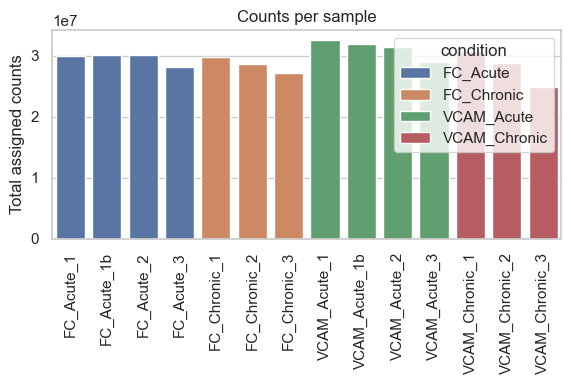

,total_counts
count,1.400000e+01
mean,2.950199e+07
std,2.013870e+06
min,2.479850e+07
25%,2.861589e+07
50%,2.986674e+07
75%,3.061811e+07
max,3.252433e+07


In [5]:
lib = counts.sum(axis=0).rename("total_counts").to_frame().join(meta[CONDITION_COL])
lib.to_csv(OUTDIR / "counts_per_sample.csv")

fig, ax = plt.subplots(figsize=(max(6, 0.4 * len(lib)), 4))
sns.barplot(data=lib.rename_axis("sample").reset_index(), x="sample", y="total_counts",
            hue=CONDITION_COL, dodge=False, ax=ax)
ax.set(xlabel="", ylabel="Total assigned counts", title="Counts per sample")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout(); fig.savefig(OUTDIR / "counts_per_sample.png", dpi=150)
plt.show()
lib.describe()

## 2. Detected genes per sample

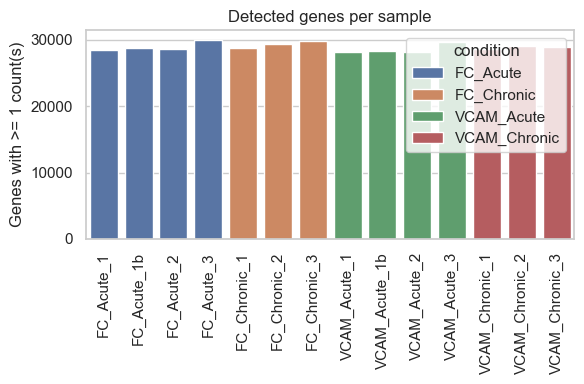

,genes_detected
count,14.000000
mean,28921.285714
std,593.126972
min,28117.000000
25%,28540.250000
50%,28811.500000
75%,29252.500000
max,29935.000000


In [6]:
det = (counts >= MIN_COUNT_DETECTED).sum(axis=0).rename("genes_detected").to_frame().join(meta[CONDITION_COL])
det.to_csv(OUTDIR / "genes_per_sample.csv")

fig, ax = plt.subplots(figsize=(max(6, 0.4 * len(det)), 4))
sns.barplot(data=det.rename_axis("sample").reset_index(), x="sample", y="genes_detected",
            hue=CONDITION_COL, dodge=False, ax=ax)
ax.set(xlabel="", ylabel=f"Genes with >= {MIN_COUNT_DETECTED} count(s)", title="Detected genes per sample")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout(); fig.savefig(OUTDIR / "genes_per_sample.png", dpi=150)
plt.show()
det.describe()

## 3. PCA
log2-CPM of the top most-variable genes (similar to DESeq2's `plotPCA`).

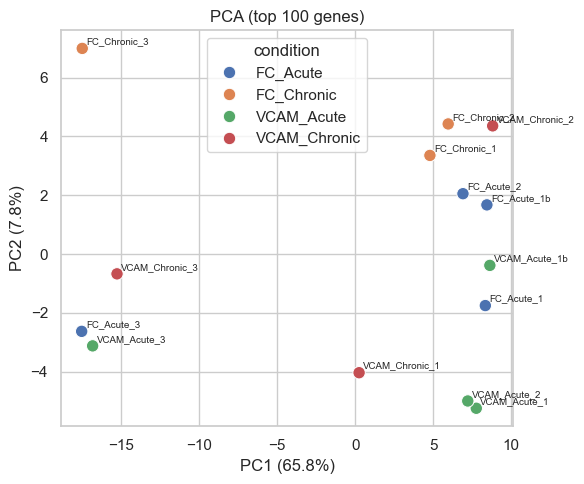

In [7]:
logcpm = np.log2(counts / counts.sum(axis=0) * 1e6 + 1)
top = logcpm.var(axis=1).sort_values(ascending=False).index[:N_TOP_PCA]
X = logcpm.loc[top].T
X = X - X.mean(axis=0)

pca = PCA(n_components=min(5, X.shape[0]))
pcs = pca.fit_transform(X)
var = pca.explained_variance_ratio_ * 100

pc_df = pd.DataFrame(pcs[:, :2], index=X.index, columns=["PC1", "PC2"]).join(meta[CONDITION_COL])
pc_df.to_csv(OUTDIR / "pca_coordinates.csv")

fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue=CONDITION_COL, s=80, ax=ax)
for s, row in pc_df.iterrows():
    ax.annotate(s, (row.PC1, row.PC2), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel=f"PC1 ({var[0]:.1f}%)", ylabel=f"PC2 ({var[1]:.1f}%)", title=f"PCA (top {N_TOP_PCA} genes)")
fig.tight_layout(); fig.savefig(OUTDIR / "pca.png", dpi=150)
plt.show()

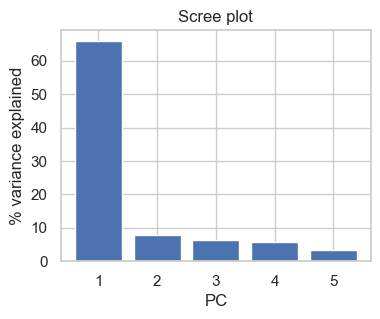

In [8]:
# Scree plot
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(range(1, len(var) + 1), var)
ax.set(xlabel="PC", ylabel="% variance explained", title="Scree plot")
plt.show()

## 4. Differential expression (PyDESeq2)

In [9]:
keep = counts.sum(axis=1) >= MIN_TOTAL_COUNTS
counts_f = counts.loc[keep]
print(f"Keeping {keep.sum()} / {len(keep)} genes with >= {MIN_TOTAL_COUNTS} total counts")

inference = DefaultInference(n_cpus=N_CPUS)
dds = DeseqDataSet(
    counts=counts_f.T,        # samples x genes
    metadata=meta,
    design=DESIGN,
    refit_cooks=True,
    inference=inference,
)
dds.deseq2()

Keeping 28636 / 78289 genes with >= 10 total counts
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.91 seconds.

Fitting dispersion trend curve...
... done in 0.27 seconds.

Fitting MAP dispersions...
... done in 2.29 seconds.

Fitting LFCs...
... done in 1.36 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [10]:
ds = DeseqStats(dds, contrast=[CONDITION_COL, TEST, REFERENCE], inference=inference)
ds.summary()
# Optional LFC shrinkage:
# ds.lfc_shrink(coeff=f"{CONDITION_COL}[T.{TEST}]")

res = ds.results_df.copy()
res.insert(0, "gene_name", gene_names.reindex(res.index))
res = res.sort_values("padj")
res.to_csv(OUTDIR / f"deseq2_{TEST}_vs_{REFERENCE}.csv")

sig = res[(res.padj < PADJ_THR) & (res.log2FoldChange.abs() >= LFC_THR)]
sig.to_csv(OUTDIR / f"deseq2_{TEST}_vs_{REFERENCE}_significant.csv")
print(f"{len(sig)} significant genes (padj < {PADJ_THR}, |log2FC| >= {LFC_THR}): "
      f"{(sig.log2FoldChange > 0).sum()} up, {(sig.log2FoldChange < 0).sum()} down")
sig.head(20)

Running Wald tests...


Log2 fold change & Wald test p-value: condition VCAM_Acute vs FC_Acute
                          baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                                  
ENSMUSG00000000001.6   1597.414595        0.134402  0.117936  1.139621   
ENSMUSG00000000028.17    24.208863        0.178159  0.282551  0.630536   
ENSMUSG00000000031.20    15.016444        0.233426  0.850701  0.274392   
ENSMUSG00000000037.19    32.075251       -0.222258  0.725391 -0.306397   
ENSMUSG00000000049.13     4.500284       -0.849302  0.639671 -1.327717   
...                            ...             ...       ...       ...   
ENSMUSG00002076896.1     38.189031       -0.271828  0.345011 -0.787882   
ENSMUSG00002076939.1      2.260991        0.819093  1.606668  0.509809   
ENSMUSG00002076954.1      0.996119        0.679796  2.066812  0.328910   
ENSMUSG00002076982.1      1.005565       -0.592683  2.545421 -0.232843   
ENSMUSG00002076983.1      2.373768       

... done in 0.51 seconds.



,gene_name,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_id,,,,,,,
ENSMUSG00000022126.7,Acod1,23.894290,-6.518871,1.064892,-6.121626,9.262544e-10,0.000026
ENSMUSG00000024401.15,Tnf,16.248825,-6.703945,1.196003,-5.605289,2.079075e-08,0.000297


### Volcano plot

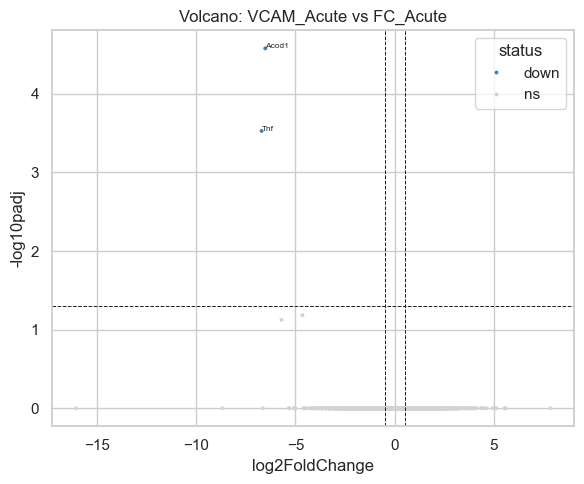

In [11]:
vdf = res.dropna(subset=["padj"]).copy()
vdf["-log10padj"] = -np.log10(vdf.padj.clip(lower=1e-300))
vdf["status"] = "ns"
vdf.loc[(vdf.padj < PADJ_THR) & (vdf.log2FoldChange >= LFC_THR), "status"] = "up"
vdf.loc[(vdf.padj < PADJ_THR) & (vdf.log2FoldChange <= -LFC_THR), "status"] = "down"

fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=vdf, x="log2FoldChange", y="-log10padj", hue="status",
                palette={"ns": "lightgrey", "up": "firebrick", "down": "steelblue"},
                s=8, linewidth=0, ax=ax)
ax.axhline(-np.log10(PADJ_THR), ls="--", c="k", lw=0.7)
for x in (LFC_THR, -LFC_THR):
    ax.axvline(x, ls="--", c="k", lw=0.7)
for g, row in vdf[vdf.status != "ns"].nsmallest(15, "padj").iterrows():
    ax.annotate(row.gene_name if pd.notna(row.gene_name) else g,
                (row.log2FoldChange, row["-log10padj"]), fontsize=6)
ax.set_title(f"Volcano: {TEST} vs {REFERENCE}")
fig.tight_layout(); fig.savefig(OUTDIR / f"volcano_{TEST}_vs_{REFERENCE}.png", dpi=150)
plt.show()

### MA plot

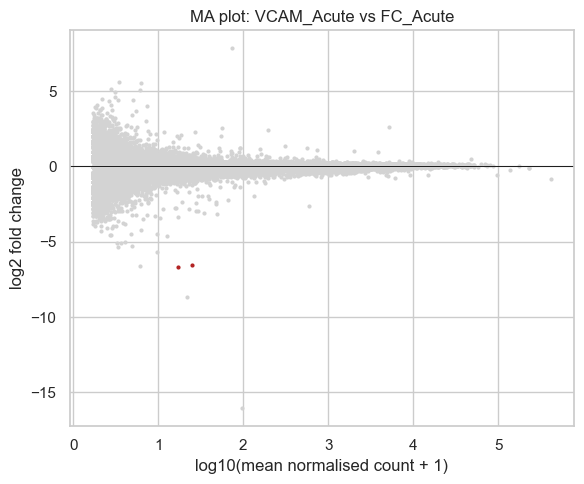

In [12]:
mdf = res.dropna(subset=["padj"])
is_sig = mdf.padj < PADJ_THR
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(np.log10(mdf.baseMean[~is_sig] + 1), mdf.log2FoldChange[~is_sig], s=4, c="lightgrey")
ax.scatter(np.log10(mdf.baseMean[is_sig] + 1), mdf.log2FoldChange[is_sig], s=4, c="firebrick")
ax.axhline(0, c="k", lw=0.7)
ax.set(xlabel="log10(mean normalised count + 1)", ylabel="log2 fold change", title=f"MA plot: {TEST} vs {REFERENCE}")
fig.tight_layout(); fig.savefig(OUTDIR / f"ma_{TEST}_vs_{REFERENCE}.png", dpi=150)
plt.show()

### Heatmap of top DEGs

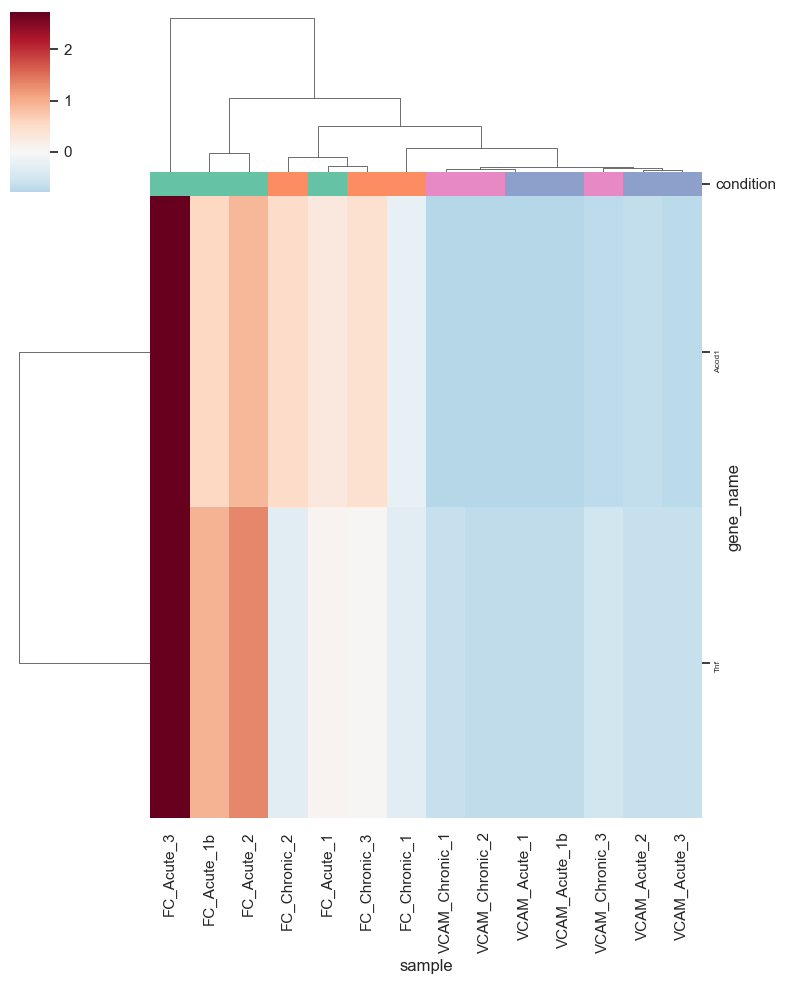

In [13]:
top_genes = sig.index[:50]
if len(top_genes) > 1:
    norm = np.log2(counts.loc[top_genes] / counts.sum(axis=0) * 1e6 + 1)
    z = norm.sub(norm.mean(axis=1), axis=0).div(norm.std(axis=1), axis=0)
    z.index = gene_names.reindex(z.index).fillna(pd.Series(z.index, index=z.index))
    lut = dict(zip(meta[CONDITION_COL].unique(), sns.color_palette("Set2")))
    g = sns.clustermap(z, cmap="RdBu_r", center=0, col_colors=meta[CONDITION_COL].map(lut),
                       figsize=(8, 10), yticklabels=True)
    g.ax_heatmap.tick_params(axis="y", labelsize=6)
    g.savefig(OUTDIR / f"heatmap_top_{TEST}_vs_{REFERENCE}.png", dpi=150)
    plt.show()
else:
    print("Fewer than 2 significant genes; skipping heatmap.")